# Задача №7: Расчет ТСО и выбор инфраструктурной стратегии

## Цель работы
Рассчитать совокупную стоимость владения (ТСО) для трех вариантов ИТ-инфраструктуры государственного информационного портала на горизонте 5 лет и выбрать экономически наиболее эффективную стратегию.

## Исходные данные

### Вариант 1: On-premise ЦОД
| Параметр | Значение |
|---|---|
| Приобретение оборудования и ПО (разово) | 85 млн руб. |
| Настройка и интеграция (разово) | 12 млн руб. |
| Ежегодная эксплуатация (электричество, охлаждение) | 4.5 млн руб. |
| Персонал (администрирование, поддержка) | 9.0 млн руб./год |
| Обновление ПО (ежегодно) | 2.5 млн руб. |
| Обучение (разово, 1-й год) | 1.5 млн руб. |
| Простои и восстановление (в среднем) | 3.0 млн руб./год |
| Модернизация (через 3 года) | 8.0 млн руб. |

### Вариант 2: Облачный провайдер (IaaS + PaaS)
| Параметр | Значение |
|---|---|
| Настройка и миграция (разово) | 5.0 млн руб. |
| Облачные услуги (ежегодно) | 16.0 млн руб. (с ростом 5% в год) |
| Персонал (администрирование) | 4.0 млн руб./год |
| Поддержка провайдера | 2.5 млн руб./год |
| Обучение (разово, 1-й год) | 2.0 млн руб. |

### Вариант 3: Гибридная стратегия
| Параметр | Значение |
|---|---|
| Приобретение оборудования (разово) | 35.0 млн руб. |
| Настройка и интеграция (разово) | 8.0 млн руб. |
| Облачные услуги (ежегодно) | 8.0 млн руб. |
| Эксплуатация (ежегодно) | 3.0 млн руб. |
| Персонал (ежегодно) | 6.0 млн руб. |
| Поддержка (ежегодно) | 2.0 млн руб. |
| Модернизация (через 3 года) | 4.0 млн руб. |

### Дополнительные параметры
| Параметр | Значение |
|---|---|
| Ставка дисконтирования | 12% |
| Горизонт планирования | 5 лет |
| Налог на имущество (On-premise) | 2.2% от остаточной стоимости |
| Амортизация (On-premise) | Линейная, 5 лет |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Настройка стиля графиков
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# --- Ввод исходных данных ---
r = 0.12
horizon = 5

print("Исходные данные загружены.")

Исходные данные загружены.


## Часть 1. Расчет ТСО для каждого варианта

Рассчитаем ежегодные денежные потоки (затраты) для каждого варианта. 
**ТСО** рассчитывается как сумма дисконтированных затрат:
$$TCO = \sum_{t=0}^{T} \frac{CAPEX_t + OPEX_t + \text{Скрытые затраты}_t}{(1+r)^t}$$

Где:
- $t$ — год (0-5).
- $CAPEX$ — капитальные затраты.
- $OPEX$ — операционные затраты.
- $r$ — ставка дисконтирования (12%).

In [2]:
# Создаем словарь для хранения денежных потоков
cash_flows = {}

# --- Вариант 1: On-premise ---
# Для налога на имущество используем линейную амортизацию
equip_cost_onprem = 85.0
depreciation = equip_cost_onprem / horizon

# Рассчитаем остаточную стоимость и налог на имущество для каждого года
# Налог считается от среднегодовой стоимости (начало + конец) / 2
onprem_cf = [0] * (horizon + 1)
onprem_cf[0] = 85.0 + 12.0 + 1.5  # Оборудование + Интеграция + Обучение

# Переменные для расчета налога
residual_value = equip_cost_onprem
tax_rate = 0.022

for year in range(1, horizon + 1):
    # Текущие затраты
    opex = 4.5 + 9.0 + 2.5 + 3.0  # Эксплуатация + Персонал + ПО + Простои
    
    # Налог на имущество (от среднегодовой стоимости)
    # В год модернизации (3-й) стоимость увеличивается
    modern_cost = 8.0 if year == 3 else 0.0
    
    # Среднегодовая стоимость = (Начало года + Конец года) / 2
    begin_value = residual_value
    end_value = begin_value - depreciation + modern_cost
    avg_value = (begin_value + end_value) / 2
    property_tax = avg_value * tax_rate
    
    # Обновляем остаточную стоимость для следующего года
    residual_value = end_value
    
    onprem_cf[year] = opex + modern_cost + property_tax

cash_flows['On-premise'] = onprem_cf

# --- Вариант 2: Облако ---
cloud_cf = [0] * (horizon + 1)
cloud_cf[0] = 5.0 + 2.0  # Настройка + Обучение

for year in range(1, horizon + 1):
    # Облачные услуги с ростом 5% в год
    cloud_services = 16.0 * (1.05 ** (year - 1))
    opex = cloud_services + 4.0 + 2.5  # Услуги + Персонал + Поддержка
    cloud_cf[year] = opex

cash_flows['Cloud'] = cloud_cf

# --- Вариант 3: Гибрид ---
hybrid_cf = [0] * (horizon + 1)
hybrid_cf[0] = 35.0 + 8.0  # Оборудование + Интеграция

# Для гибрида также считаем налог на имущество (упрощенно, как для On-premise)
equip_cost_hybrid = 35.0
depreciation_hybrid = equip_cost_hybrid / horizon
residual_value_hybrid = equip_cost_hybrid

for year in range(1, horizon + 1):
    opex = 8.0 + 3.0 + 6.0 + 2.0  # Облако + Эксплуатация + Персонал + Поддержка
    
    modern_cost = 4.0 if year == 3 else 0.0
    
    begin_value = residual_value_hybrid
    end_value = begin_value - depreciation_hybrid + modern_cost
    avg_value = (begin_value + end_value) / 2
    property_tax = avg_value * tax_rate
    
    residual_value_hybrid = end_value
    
    hybrid_cf[year] = opex + modern_cost + property_tax

cash_flows['Hybrid'] = hybrid_cf

# Вывод денежных потоков в таблице
cf_df = pd.DataFrame(cash_flows, index=[f'Year {i}' for i in range(horizon + 1)])
cf_df = cf_df.transpose()
print("Ежегодные затраты (млн руб.):")
display(cf_df.round(2))

Ежегодные затраты (млн руб.):


,Year 0,Year 1,Year 2,Year 3,Year 4,Year 5
On-premise,98.5,20.68,20.31,28.02,19.74,19.36
Cloud,7.0,22.50,23.30,24.14,25.02,25.95
Hybrid,43.0,19.69,19.54,23.43,19.32,19.16


## Часть 2. Дисконтирование и расчет ТСО

Теперь продисконтируем денежные потоки и найдем суммарный ТСО для каждого варианта.

**Формула:**
$$PV_t = \frac{CF_t}{(1+r)^t}$$
$$TCO = \sum_{t=0}^{5} PV_t$$

Где $r = 12\%$.

In [3]:
# Словарь для хранения дисконтированных потоков и ТСО
discounted_cf = {}
tco_results = {}

for variant, cf in cash_flows.items():
    discounted = []
    total_tco = 0
    for t, value in enumerate(cf):
        pv = value / ((1 + r) ** t)
        discounted.append(pv)
        total_tco += pv
    discounted_cf[variant] = discounted
    tco_results[variant] = total_tco

# Вывод результатов
print("Суммарный ТСО за 5 лет (млн руб.):")
for variant, tco in sorted(tco_results.items(), key=lambda x: x[1]):
    print(f"{variant}: {tco:.2f}")

# Определение лучшего варианта
best_variant = min(tco_results, key=tco_results.get)
print(f"\nНаименьший ТСО у варианта: {best_variant}")

# Таблица дисконтированных потоков
dcf_df = pd.DataFrame(discounted_cf, index=[f'Year {i}' for i in range(horizon + 1)]).transpose()
print("\nДисконтированные затраты (млн руб.):")
display(dcf_df.round(2))

Суммарный ТСО за 5 лет (млн руб.):
Cloud: 93.47
Hybrid: 115.99
On-premise: 176.63

Наименьший ТСО у варианта: Cloud

Дисконтированные затраты (млн руб.):


,Year 0,Year 1,Year 2,Year 3,Year 4,Year 5
On-premise,98.5,18.47,16.19,19.95,12.54,10.99
Cloud,7.0,20.09,18.57,17.18,15.90,14.72
Hybrid,43.0,17.58,15.58,16.68,12.28,10.87


## Часть 2.2. Точка безубыточности (On-premise vs Cloud vs Hybrid)

Точка безубыточности (Break-Even Point) — это год, в котором накопленные дисконтированные затраты двух стратегий сравниваются.

**Метод:** 
1. Считаем накопленные PV (кумулятивная сумма дисконтированных потоков) по годам для каждого варианта.
2. Находим разницу между накопленными PV On-premise и Cloud.
3. Если знак разницы меняется — линии пересекаются, точка безубыточности найдена.

**Формула:**
$$\text{CumPV}_t = \sum_{i=0}^{t} PV_i, \quad \Delta_t = \text{CumPV}_t^{Onprem} - \text{CumPV}_t^{Cloud}$$

Точка безубыточности — это такое $t^*$, при котором $\Delta_{t^*} = 0$.

Точка безубыточности не достигается за горизонт планирования.

In [4]:
# Накопленные дисконтированные затраты по годам
cum_onprem = np.cumsum(discounted_cf['On-premise'])
cum_cloud  = np.cumsum(discounted_cf['Cloud'])
cum_hybrid = np.cumsum(discounted_cf['Hybrid'])

breakeven_df = pd.DataFrame({
    'Год': range(horizon + 1),
    'PV On-premise (кум.)': cum_onprem,
    'PV Cloud (кум.)': cum_cloud,
    'PV Hybrid (кум.)': cum_hybrid,
    'Разница (On-prem - Cloud)': cum_onprem - cum_cloud,
    'Разница (On-prem - Hybrid)': cum_onprem - cum_hybrid,
}).set_index('Год')

print("Накопленные дисконтированные затраты и разница (млн руб.):")
display(breakeven_df.round(2))

# Проверка пересечения линий
def check_cross(a, b, name_a, name_b):
    signs = np.sign(a - b)
    for i in range(1, len(signs)):
        if signs[i] != signs[i-1] and signs[i] != 0 and signs[i-1] != 0:
            print(f"✅ Точка безубыточности {name_a} vs {name_b}: между годом {i-1} и {i}.")
            return True
    print(f"❌ {name_a} vs {name_b}: линии не пересекаются за {horizon} лет. "
          f"{name_a if a[-1] > b[-1] else name_b} стабильно дешевле.")
    return False

print()
check_cross(cum_onprem, cum_cloud, 'On-premise', 'Cloud')
check_cross(cum_onprem, cum_hybrid, 'On-premise', 'Hybrid')
check_cross(cum_hybrid, cum_cloud, 'Hybrid', 'Cloud')

Накопленные дисконтированные затраты и разница (млн руб.):


,PV On-premise (кум.),PV Cloud (кум.),PV Hybrid (кум.),Разница (On-prem - Cloud),Разница (On-prem - Hybrid)
Год,,,,,
0,98.50,7.00,43.00,91.50,55.50
1,116.97,27.09,60.58,89.88,56.38
2,133.16,45.66,76.16,87.49,57.00
3,153.10,62.85,92.84,90.26,60.27
4,165.65,78.75,105.11,86.90,60.53
5,176.63,93.47,115.99,83.16,60.65



❌ On-premise vs Cloud: линии не пересекаются за 5 лет. On-premise стабильно дешевле.
❌ On-premise vs Hybrid: линии не пересекаются за 5 лет. On-premise стабильно дешевле.
❌ Hybrid vs Cloud: линии не пересекаются за 5 лет. Hybrid стабильно дешевле.


False

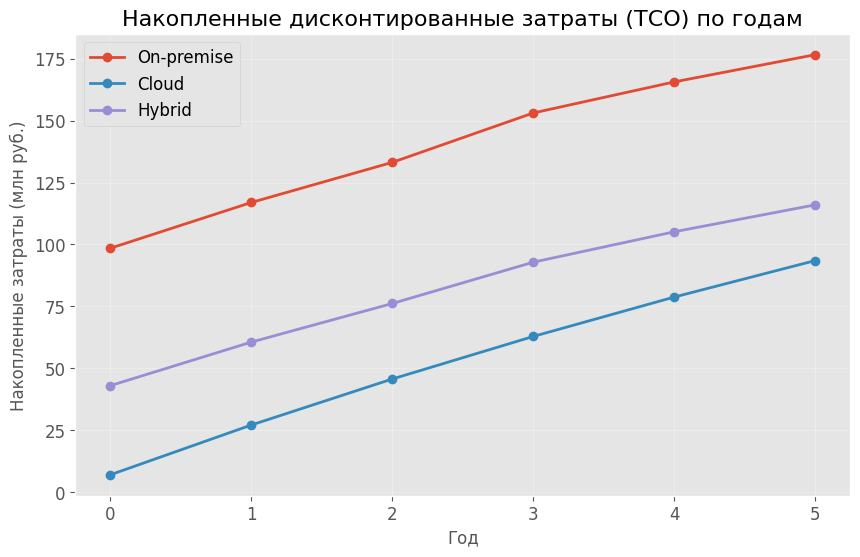

In [6]:
# Построение графика накопленных дисконтированных затрат
plt.figure(figsize=(10, 6))

for variant, dcf in discounted_cf.items():
    cumulative = np.cumsum(dcf)
    plt.plot(range(horizon + 1), cumulative, marker='o', label=variant, linewidth=2)

plt.title('Накопленные дисконтированные затраты (ТСО) по годам', fontsize=16)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Накопленные затраты (млн руб.)', fontsize=12)
plt.xticks(range(horizon + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Часть 3. Анализ чувствительности

Проверим, как изменение ключевых параметров влияет на выбор стратегии.

### 3.1. Чувствительность к ставке дисконтирования
Рассмотрим ставки 8%, 12% и 16%.

### 3.2. Чувствительность к стоимости облачных услуг
Рассмотрим изменение стоимости облачных услуг на ±20%.

In [7]:
# 3.1. Анализ чувствительности к ставке дисконтирования
rates = [0.08, 0.12, 0.16]
sensitivity_r = []

for rate in rates:
    tco_at_rate = {}
    for variant, cf in cash_flows.items():
        total = sum(value / ((1 + rate) ** t) for t, value in enumerate(cf))
        tco_at_rate[variant] = total
    sensitivity_r.append({'Rate': f'{rate*100:.0f}%', **tco_at_rate})

sensitivity_r_df = pd.DataFrame(sensitivity_r)
print("Чувствительность ТСО к ставке дисконтирования (млн руб.):")
display(sensitivity_r_df.round(2))

Чувствительность ТСО к ставке дисконтирования (млн руб.):


,Rate,On-premise,Cloud,Hybrid
0,8%,184.99,103.02,123.83
1,12%,176.63,93.47,115.99
2,16%,169.50,85.35,109.30


In [8]:
# 3.2. Анализ чувствительности к стоимости облачных услуг (±20%)
multipliers = [0.8, 1.0, 1.2]
sensitivity_cloud = []

# Для облачного варианта
for mult in multipliers:
    # Пересчитываем денежные потоки для облака
    cloud_cf_adj = [0] * (horizon + 1)
    cloud_cf_adj[0] = 5.0 + 2.0
    for year in range(1, horizon + 1):
        cloud_services = 16.0 * (1.05 ** (year - 1)) * mult
        opex = cloud_services + 4.0 + 2.5
        cloud_cf_adj[year] = opex
    
    # Дисконтируем
    total_tco = sum(value / ((1 + r) ** t) for t, value in enumerate(cloud_cf_adj))
    sensitivity_cloud.append({'Multiplier': f'{mult*100:.0f}%', 'Cloud TCO': total_tco})

sensitivity_cloud_df = pd.DataFrame(sensitivity_cloud)
print("Чувствительность ТСО облака к изменению стоимости услуг:")
display(sensitivity_cloud_df.round(2))

# Сравнение с On-premise и Hybrid
print(f"\nДля сравнения: On-premise = {tco_results['On-premise']:.2f} млн, Hybrid = {tco_results['Hybrid']:.2f} млн")

Чувствительность ТСО облака к изменению стоимости услуг:


,Multiplier,Cloud TCO
0,80%,80.86
1,100%,93.47
2,120%,106.08



Для сравнения: On-premise = 176.63 млн, Hybrid = 115.99 млн


## Часть 4. Стратегические рекомендации

### 4.1. Обоснование выбора

На основе расчетов, вариант **Cloud** имеет наименьший ТСО (**≈93.47 млн руб.**) на горизонте 5 лет.

**Ключевые преимущества:**
- Наименьшие начальные затраты (CAPEX).
- Предсказуемость операционных затрат (OPEX).
- Гибкость масштабирования.

### 4.2. Дополнительные факторы для учета
При принятии окончательного решения необходимо учесть:
1. **Безопасность данных:** Для обработки персональных данных может потребоваться On-premise или гибрид.
2. **Регуляторные требования (ФЗ-152):** Требуется анализ локализации данных.
3. **Долгосрочные перспективы:** При горизонте >7 лет On-premise может стать выгоднее.
4. **Текущий штат:** Наличие квалифицированных администраторов для облака.

### 4.3. Рекомендации по внедрению
1. Выбрать облачного провайдера с сертификацией (ФСТЭК).
2. Заключить долгосрочный контракт с фиксацией цен.
3. Провести обучение персонала.
4. Реализовать пилотный проект на 3 месяца.

## Итоговый вывод

В результате расчетов было установлено, что **облачная стратегия (IaaS + PaaS)** является экономически наиболее эффективной на горизонте 5 лет. Суммарный ТСО составляет **≈93.47 млн руб.**, что на **47%** ниже, чем у On-premise (176.63 млн руб.), и на **19%** ниже, чем у гибридной стратегии (115.99 млн руб.).